In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas import Series, DataFrame

In [42]:
movie = pd.read_csv(r'C:\Users\divya\OneDrive\Desktop\New folder\imdb\imdb_movies.csv')
pd.set_option("display.max_columns", 24)


In [26]:
movie.drop_duplicates(inplace=True)
movie.dropna(subset=['genres'], inplace=True)

In [68]:
movie.head()

,id,imdb_id,popularity,budget,revenue,original_title,cast,homepage,director,tagline,keywords,overview,runtime,release_date,vote_count,vote_average,release_year,budget_adj,revenue_adj,Profit,genres
0,135397,tt0369610,32.99,150000000,1513528810,Jurassic World,Chris Pratt|Bryce Dallas Howard|Irrfan Khan|Vi...,http://www.jurassicworld.com/,Colin Trevorrow,The park is open.,monster|dna|tyrannosaurus rex|velociraptor|island,Twenty-two years after the events of Jurassic ...,124,6/9/15,5562,6.50,2015,137999939.28,1392445892.52,1363528810,Action
0,135397,tt0369610,32.99,150000000,1513528810,Jurassic World,Chris Pratt|Bryce Dallas Howard|Irrfan Khan|Vi...,http://www.jurassicworld.com/,Colin Trevorrow,The park is open.,monster|dna|tyrannosaurus rex|velociraptor|island,Twenty-two years after the events of Jurassic ...,124,6/9/15,5562,6.50,2015,137999939.28,1392445892.52,1363528810,Adventure
0,135397,tt0369610,32.99,150000000,1513528810,Jurassic World,Chris Pratt|Bryce Dallas Howard|Irrfan Khan|Vi...,http://www.jurassicworld.com/,Colin Trevorrow,The park is open.,monster|dna|tyrannosaurus rex|velociraptor|island,Twenty-two years after the events of Jurassic ...,124,6/9/15,5562,6.50,2015,137999939.28,1392445892.52,1363528810,Science Fiction
0,135397,tt0369610,32.99,150000000,1513528810,Jurassic World,Chris Pratt|Bryce Dallas Howard|Irrfan Khan|Vi...,http://www.jurassicworld.com/,Colin Trevorrow,The park is open.,monster|dna|tyrannosaurus rex|velociraptor|island,Twenty-two years after the events of Jurassic ...,124,6/9/15,5562,6.50,2015,137999939.28,1392445892.52,1363528810,Thriller
0,135397,tt0369610,32.99,150000000,1513528810,Jurassic World,Chris Pratt|Bryce Dallas Howard|Irrfan Khan|Vi...,http://www.jurassicworld.com/,Colin Trevorrow,The park is open.,monster|dna|tyrannosaurus rex|velociraptor|island,Twenty-two years after the events of Jurassic ...,124,6/9/15,5562,6.50,2015,137999939.28,1392445892.52,1363528810,NaN


In [59]:
movie['Profit'] = movie['revenue'] - movie['budget']

In [60]:
movie.drop(columns=['production_companies'], inplace=True)

In [61]:
s = movie['genres'].str.split('|').apply(pd.Series).stack()
s.index = s.index.droplevel(-1)
s.name = 'genres'
movie = movie.drop('genres', axis=1).join(s)

In [62]:
movie_genre_count = (
    movie.groupby('genres')['original_title']
    .count()
    .sort_values(ascending=True)
    .reset_index()
    .rename(columns={'original_title': 'count'})
)

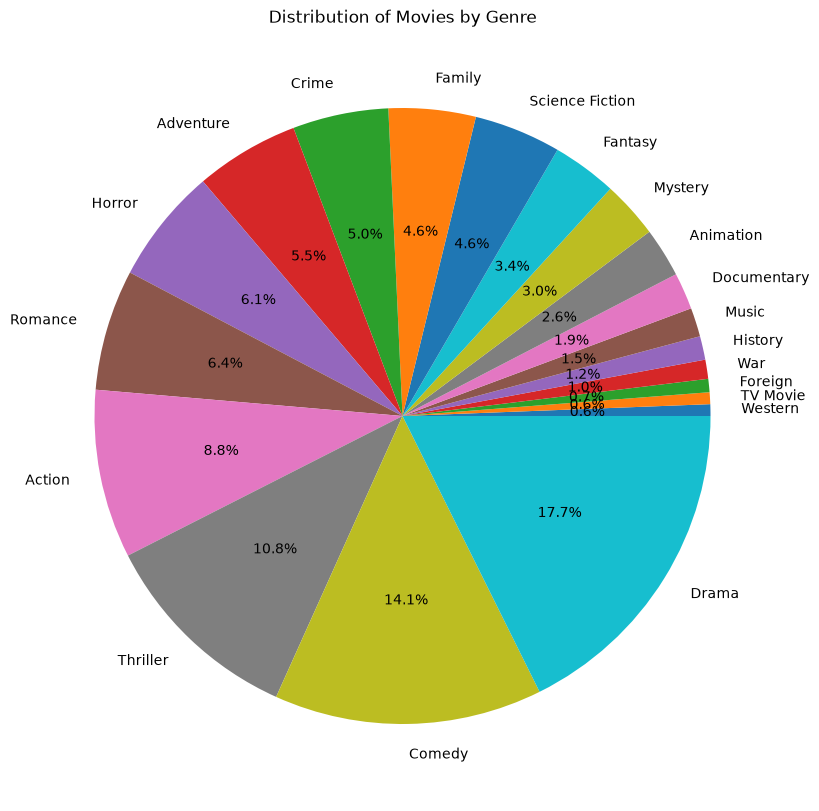

In [63]:
movie_genre_count.plot(
    kind='pie',
    y='count',
    labels=movie_genre_count['genres'],
    autopct='%1.1f%%',
    figsize=(10, 10),
    legend=False
)
plt.title('Distribution of Movies by Genre')
plt.ylabel('')
plt.show()

In [64]:
movie_genre_avg = (
    movie.groupby('genres')[['budget', 'revenue']]
    .mean()
    .sort_values(by='revenue', ascending=True)
)

In [65]:
pd.options.display.float_format = '{:.2f}'.format

In [66]:
movie_genre_avg = (
    movie.groupby('genres')[['budget', 'revenue']]
    .mean()
    .sort_values(by='revenue', ascending=True)
    .reset_index()
)

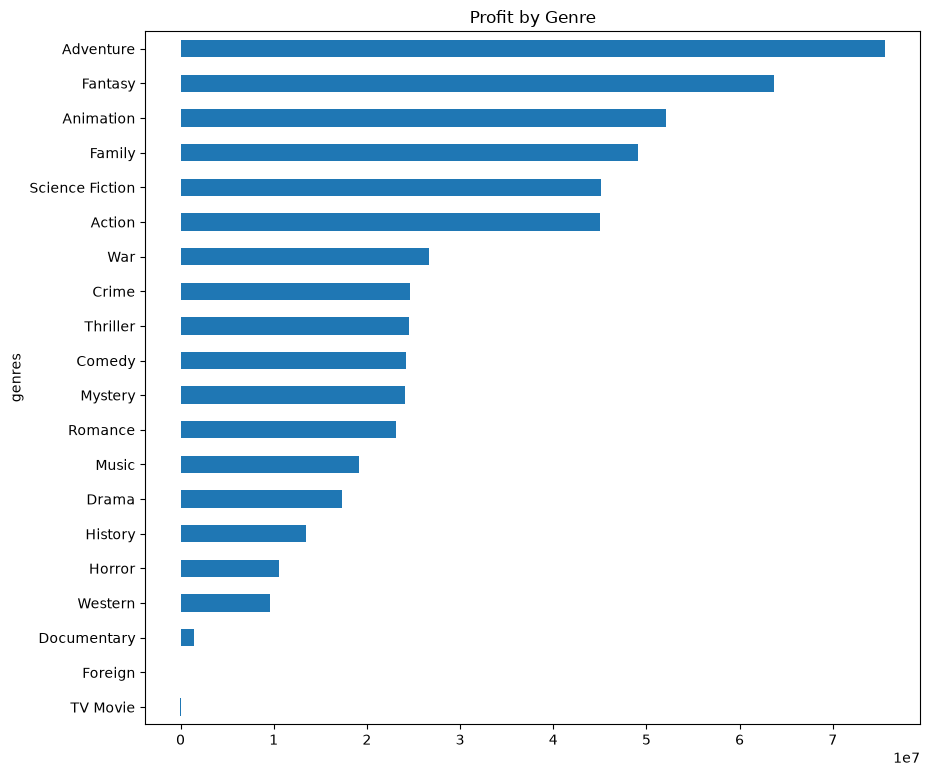

In [69]:
movie_genre_avg = movie.groupby('genres')['Profit'].mean().sort_values(ascending=True)

movie_genre_avg.plot(kind='barh', figsize=(10, 9))
plt.title('Profit by Genre')
plt.show()

In [36]:
movie_genre_count = (
    movie.groupby('genres')['original_title']
    .count()
    .sort_values(ascending=True)
    .reset_index()
    .rename(columns={'original_title': 'count'})
)

In [70]:
highest_pop = movie.groupby('genres')['popularity'].mean().sort_values(ascending=False)
print("Highest Average Popularity:\n", highest_pop.head())

print("\n" + "-" * 30 + "\n")

Highest Average Popularity:
 genres
Adventure         1.15
Science Fiction   1.00
Fantasy           0.99
Action            0.93
Animation         0.85
Name: popularity, dtype: float64

------------------------------



In [71]:
# Genres with the most movies voting >= 8
top_rated = movie[movie['vote_average'] >= 8].groupby('genres').size().sort_values(ascending=False)
print("Most Movies with Votes >= 8:\n", top_rated.head())

Most Movies with Votes >= 8:
 genres
Documentary    170
Drama          150
Music          100
Comedy          70
Crime           60
dtype: int64


Correlation Matrix:
               vote_average  popularity  budget  Profit
vote_average          1.00        0.21    0.08    0.18
popularity            0.21        1.00    0.55    0.63
budget                0.08        0.55    1.00    0.57
Profit                0.18        0.63    0.57    1.00


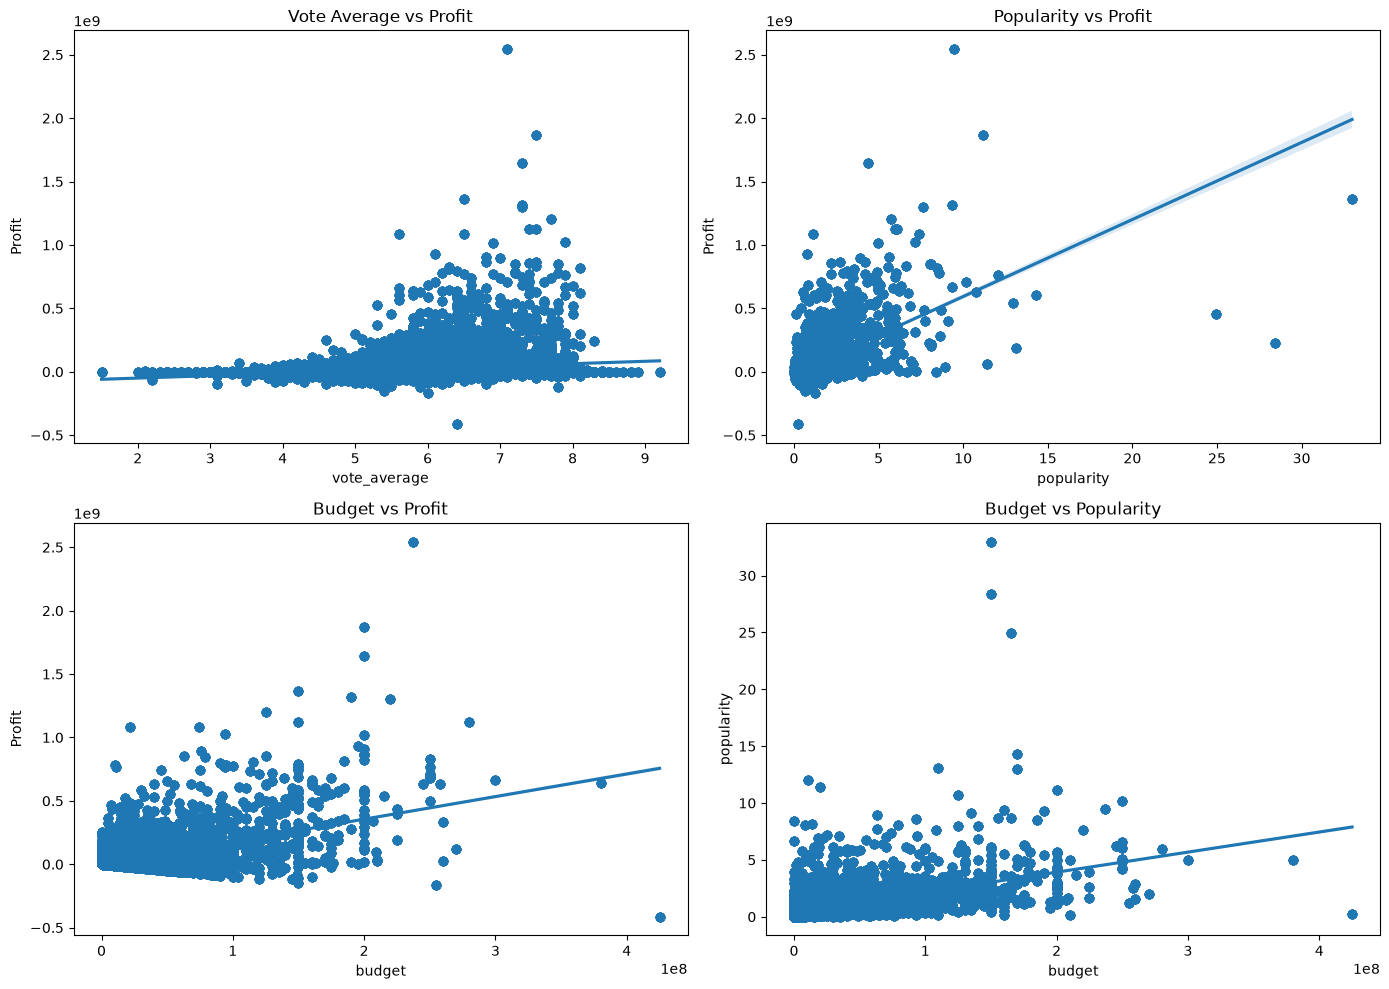

In [74]:
# Correlation matrix for the hypotheses variables
corr_cols = ['vote_average', 'popularity', 'budget', 'Profit']
print("Correlation Matrix:\n", movie[corr_cols].corr())

# Setup grid for 4 scatter/regression plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Vote Avg vs Profit
sns.regplot(data=movie, x='vote_average', y='Profit', ax=axes[0, 0], scatter_kws={'alpha':0.3})
axes[0, 0].set_title('Vote Average vs Profit')

# Plot 2: Popularity vs Profit
sns.regplot(data=movie, x='popularity', y='Profit', ax=axes[0, 1], scatter_kws={'alpha':0.3})
axes[0, 1].set_title('Popularity vs Profit')

# Plot 3: Budget vs Profit
sns.regplot(data=movie, x='budget', y='Profit', ax=axes[1, 0], scatter_kws={'alpha':0.3})
axes[1, 0].set_title('Budget vs Profit')

# Plot 4: Budget vs Popularity
sns.regplot(data=movie, x='budget', y='popularity', ax=axes[1, 1], scatter_kws={'alpha':0.3})
axes[1, 1].set_title('Budget vs Popularity')

plt.tight_layout()
plt.show()

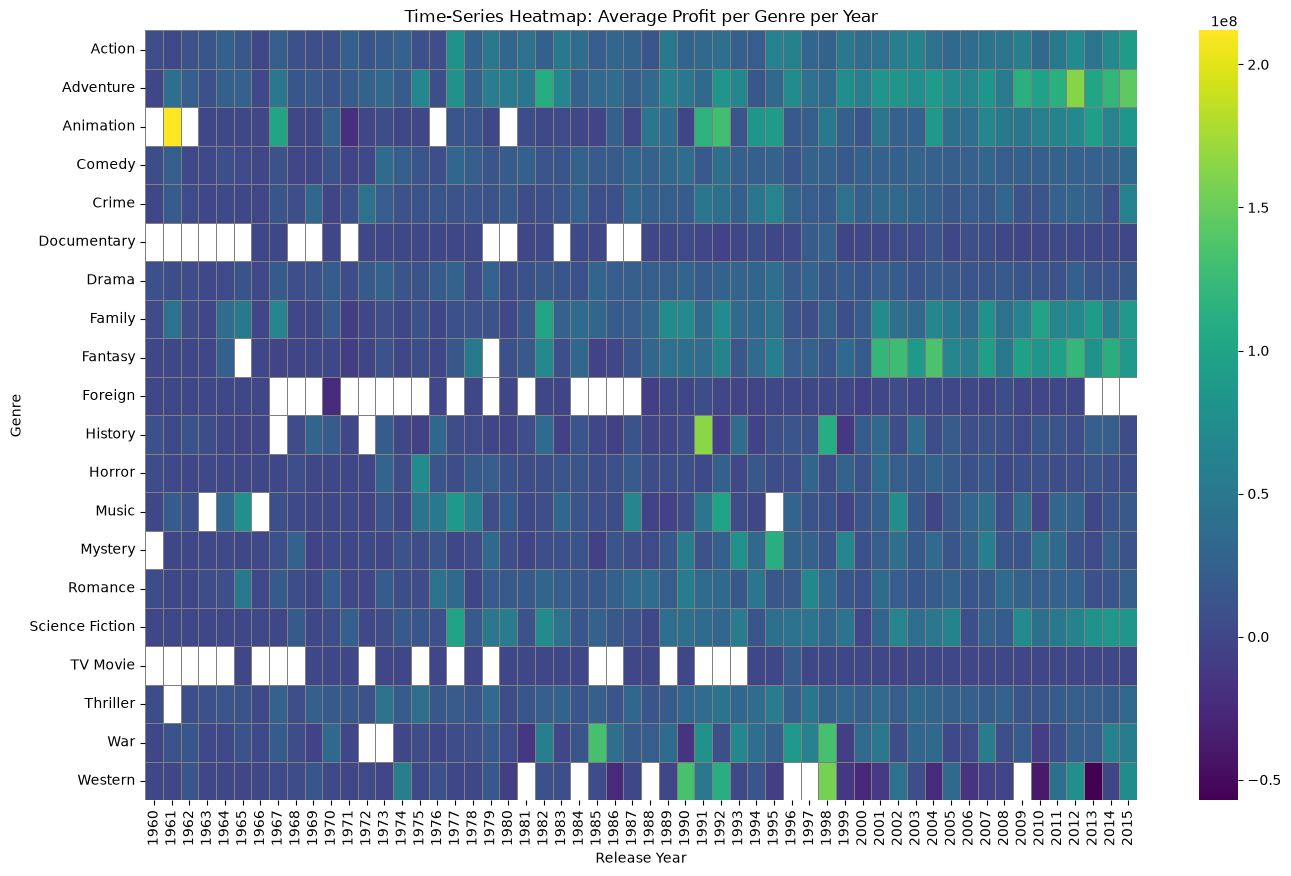

In [75]:
# Create a pivot table of Profit per genre per release year
heatmap_data = movie.pivot_table(index='genres', columns='release_year', values='Profit', aggfunc='mean')

# Plot the heatmap
plt.figure(figsize=(16, 10))
sns.heatmap(heatmap_data, cmap='viridis', linewidths=0.5, linecolor='gray')
plt.title('Time-Series Heatmap: Average Profit per Genre per Year')
plt.xlabel('Release Year')
plt.ylabel('Genre')
plt.show()